In [1]:
%pip install jinja2


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# Trabajo Práctico — Ingeniería y selección de características con RNA

**Materia:** Inteligencia Artificial  
**Modalidad:** comparación reproducible de redes neuronales con distintas selecciones de variables  
**Entorno:** Jupyter Notebook · Python 3 · scikit-learn · ucimlrepo  

### Resumen ejecutivo

Se abordan dos problemas con un mismo protocolo experimental:

| Consigna | Dataset | Tarea | Métrica principal |
|---|---|---|---|
| 1 | Appliances Energy Prediction (UCI 374) | Regresión temporal | MAE / RMSE / R² |
| 2 | Breast Cancer Wisconsin Diagnostic (UCI 17) | Clasificación binaria | Recall / F1 / Matriz de confusión |

En ambas se compara **una RNA con todas las variables** contra **la misma arquitectura con un subconjunto seleccionado**. La selección se realiza **exclusivamente con datos de entrenamiento/validación**; el conjunto de prueba se evalúa **una única vez** al final, garantizando la validez de la comparación.

## Entorno y criterio de reproducibilidad <a id="entorno"></a>

**Semilla global:** `SEED = 42` aplicada a `numpy`, `random` y a todos los estimadores con `random_state`.

**Regla metodológica (criterio común de comparación):**
> Entre configuraciones comparadas **solo cambia el conjunto de variables**.  
> Permanecen constantes: arquitectura de la RNA, función de activación, `max_iter`, particiones, semilla, pipeline de escalado y métricas de evaluación.

Esto permite atribuir las diferencias observadas a la **selección de features** y no a cambios simultáneos del experimento.

**Prevención de fuga de información:**  
Las transformaciones que aprenden parámetros (escalado, selección de features, umbrales de correlación, coeficientes de modelos auxiliares) se ajustan **solo sobre train/validación**. El conjunto de test se reserva y se evalúa **una única vez** al final de cada consigna.

In [2]:
# %pip install -q ucimlrepo scikit-learn pandas numpy matplotlib seaborn

import warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
)
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import (
    mutual_info_regression, mutual_info_classif, f_classif, RFE,
)
from sklearn.linear_model import LassoCV, LogisticRegression

# --- Reproducibilidad ---
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED)

# --- Estilo de figuras ---
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60)

print("Setup OK · seed =", SEED)

Setup OK · seed = 42


---
# Parte 1 — Regresión temporal del consumo de electrodomésticos
### *Appliances Energy Prediction · UCI ML Repository (id=374)*
---

## 1.1 Objetivo y metodología

**Objetivo.** Predecir el consumo de electrodomésticos (`Appliances`, Wh) a partir de variables ambientales y temporales, comparando una RNA entrenada con **todas las variables** contra la misma arquitectura entrenada con un **subconjunto informativo** seleccionado sin fuga.

**Características del dataset.**
- 19.735 registros muestreados cada 10 minutos.
- 28 variables predictoras: sensores de temperatura (`T*`), humedad (`RH*`), clima exterior (`T_out`, `RH_out`, `Press_mm_hg`, `Windspeed`, `Visibility`, `Tdewpoint`), iluminación (`lights`) y dos variables aleatorias de control (`rv1`, `rv2`).
- Variable objetivo continua: `Appliances` en Wh.

**Metodología.**
1. Orden cronológico por `date` y descarte de la fecha como texto.
2. Ingeniería de features temporales: `hour_sin`, `hour_cos`, `day_of_week`, `is_weekend`.
3. Análisis exploratorio: asociación con el objetivo, redundancia entre sensores, comportamiento de `rv1`/`rv2`.
4. Construcción de **cuatro subconjuntos candidatos** mediante técnicas complementarias (correlación con control de redundancia, información mutua, regularización Lasso e importancia por permutación).
5. Comparación de las cinco configuraciones (todas + cuatro subconjuntos) sobre validación.
6. Evaluación final, única, sobre test.

**Partición temporal (sin mezcla):** 70 % train · 15 % validación · 15 % test.

In [3]:
# =====================================================================
# Carga del dataset y construcción de atributos temporales
# =====================================================================
energy = fetch_ucirepo(id=374)

X_raw = energy.data.features.copy()
y_raw = energy.data.targets.squeeze().astype(float)

df = X_raw.copy()
df["Appliances"] = y_raw.to_numpy()

# --- FIX para el error de fecha: insertar un espacio si falta ---
# Algunos strings vienen como '2016-01-1117:00:00' (sin espacio).
# Esta línea separa la fecha de la hora correctamente.
df["date"] = df["date"].astype(str).apply(lambda x: x[:10] + " " + x[10:] if len(x) > 10 and x[10] != " " else x)
df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date").reset_index(drop=True)

# --- Ingeniería de features temporales (sin ingresar la fecha como texto) ---
df["hour_sin"]    = np.sin(2 * np.pi * df["date"].dt.hour / 24)
df["hour_cos"]    = np.cos(2 * np.pi * df["date"].dt.hour / 24)
df["day_of_week"] = df["date"].dt.dayofweek            # 0=lunes … 6=domingo
df["is_weekend"]  = (df["day_of_week"] >= 5).astype(int)

print("Shape:", df.shape)
print("Rango temporal:", df["date"].min(), "→", df["date"].max())
print("Nulos totales:", int(df.isna().sum().sum()))
df.head()

Shape: (19735, 33)
Rango temporal: 2016-01-11 17:00:00 → 2016-05-27 18:00:00
Nulos totales: 0


,date,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Appliances,hour_sin,hour_cos,day_of_week,is_weekend
0,2016-01-11 17:00:00,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.60,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,60.0,-0.965926,-0.258819,0,0
1,2016-01-11 17:10:00,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.48,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,60.0,-0.965926,-0.258819,0,0
2,2016-01-11 17:20:00,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.37,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,50.0,-0.965926,-0.258819,0,0
3,2016-01-11 17:30:00,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.25,733.8,92.0,6.000000,51.500000,5.0,45.410390,45.410390,50.0,-0.965926,-0.258819,0,0
4,2016-01-11 17:40:00,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.13,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,60.0,-0.965926,-0.258819,0,0


## 1.2 Análisis exploratorio

**Objetivo.** Caracterizar el objetivo, cuantificar asociaciones lineales y detectar redundancia entre sensores antes de proponer subconjuntos.

**Salida esperada.**
- Estadísticos descriptivos y distribución de `Appliances`.
- Correlación de cada predictor con el objetivo, ordenada por valor absoluto.
- Dispersión de `rv1` y `rv2` contra `Appliances` (verificación de ausencia de señal).
- Mapa de calor de correlaciones entre predictores y listado de pares con |r| > 0.95.

**Interpretación esperada.** `lights` y algunas variables horarias concentran la asociación; los sensores de temperatura y humedad forman grupos fuertemente correlacionados; `rv1` y `rv2` deben exhibir correlación ≈ 0 con el objetivo.

,count,mean,min,25%,50%,75%,max,std
date,19735,2016-03-20 05:29:59.999999,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
lights,19735.0,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,19735.0,21.686571,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,19735.0,40.259739,27.023333,37.333333,39.656667,43.066667,63.36,3.979299
T2,19735.0,20.341219,16.1,18.79,20.0,21.5,29.856667,2.192974
RH_2,19735.0,40.42042,20.463333,37.9,40.5,43.26,56.026667,4.069813
T3,19735.0,22.267611,17.2,20.79,22.1,23.29,29.236,2.006111
RH_3,19735.0,39.2425,28.766667,36.9,38.53,41.76,50.163333,3.254576
T4,19735.0,20.855335,15.1,19.53,20.666667,22.1,26.2,2.042884
RH_4,19735.0,39.026904,27.66,35.53,38.4,42.156667,51.09,4.341321



Correlación con Appliances (|r|):


,r_con_Appliances
hour_sin,-0.235233
hour_cos,-0.232125
lights,0.197278
RH_out,-0.152282
T2,0.120073
T6,0.117638
T_out,0.099155
RH_8,-0.094039
Windspeed,0.087122
RH_1,0.086031


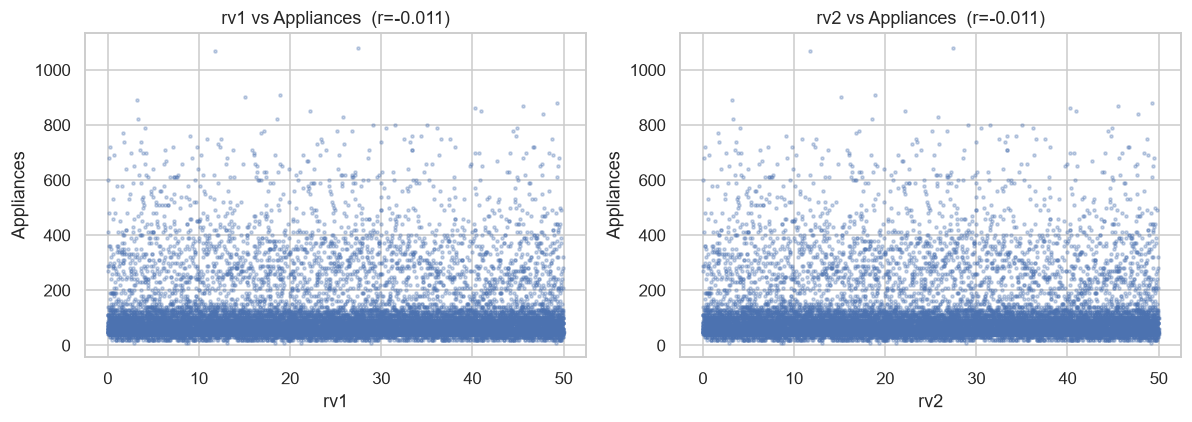

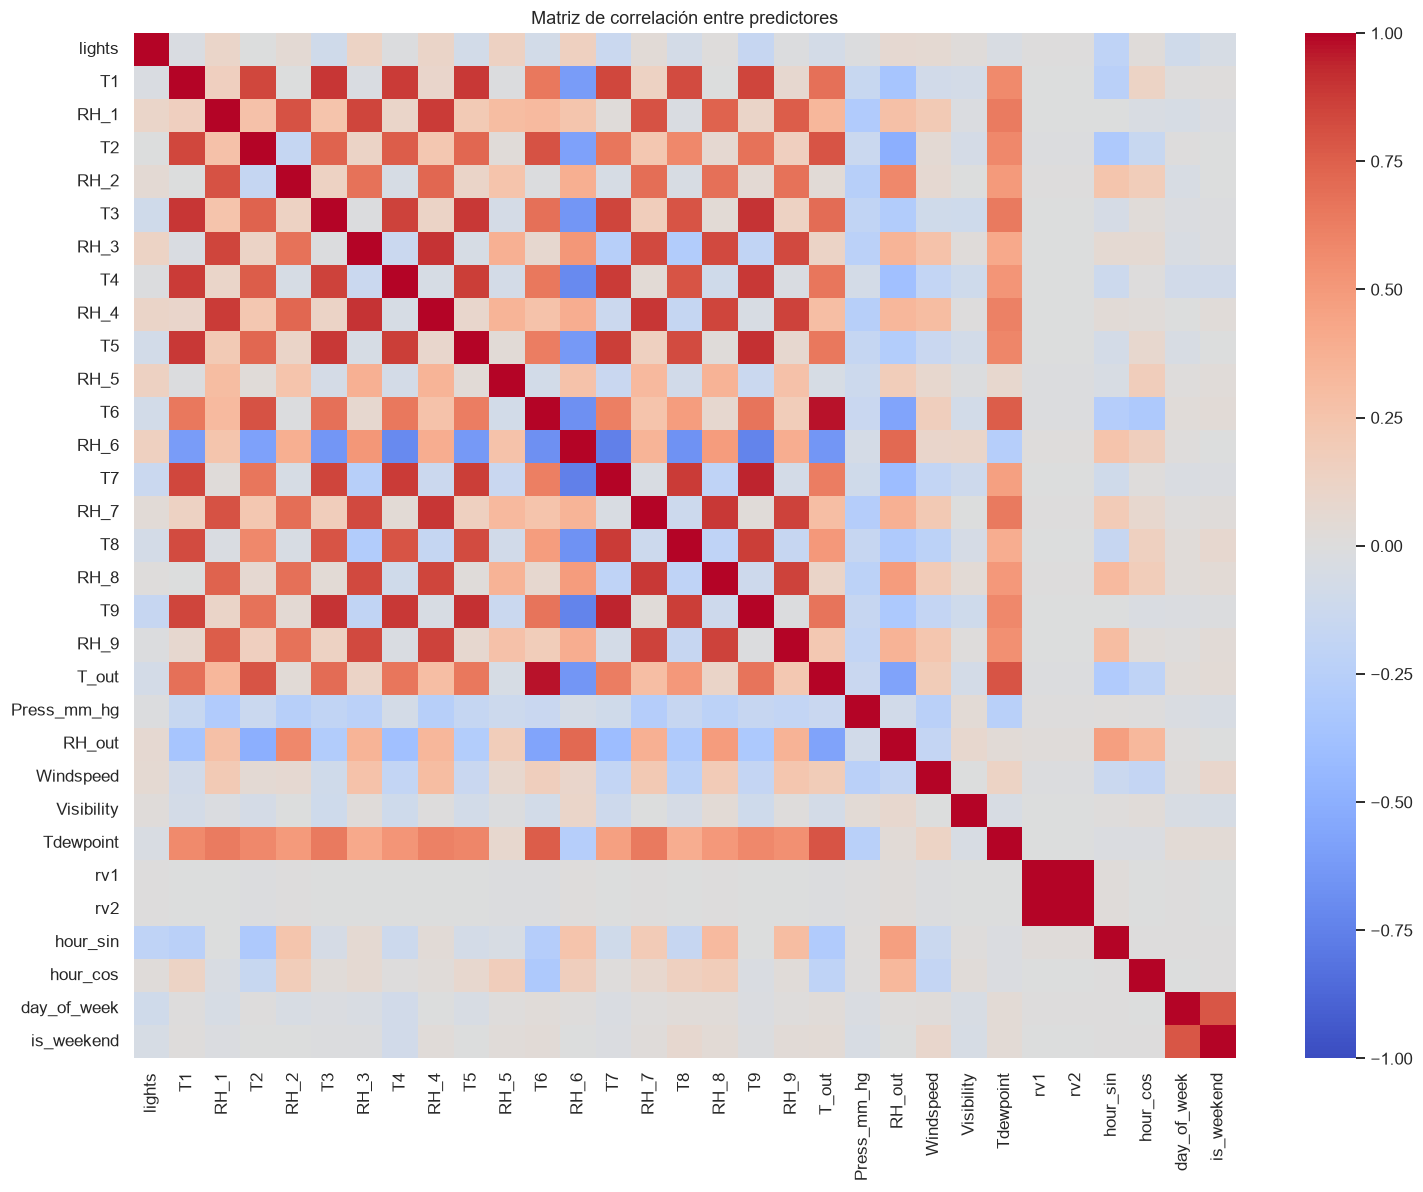

Pares con |r| > 0.95: 2
       T_out ~ T6         r=0.975
         rv2 ~ rv1        r=1.000


In [4]:
# =====================================================================
# EDA: descriptivos, asociación con el objetivo, rv1/rv2, redundancia
# =====================================================================
target   = "Appliances"
features = [c for c in df.columns if c not in ("date", target)]

display(df.describe().T)

# --- Asociación lineal con el objetivo ---
corr_target = (df[features].corrwith(df[target])
                 .sort_values(key=np.abs, ascending=False))
print("\nCorrelación con Appliances (|r|):")
display(corr_target.to_frame("r_con_Appliances").style.background_gradient(cmap="RdBu_r"))

# --- rv1 / rv2: variables de control (deben mostrar asociación ≈ 0) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, v in zip(axes, ["rv1", "rv2"]):
    ax.scatter(df[v], df[target], s=4, alpha=0.3)
    ax.set_title(f"{v} vs Appliances  (r={df[v].corr(df[target]):.3f})")
    ax.set_xlabel(v); ax.set_ylabel("Appliances")
plt.tight_layout(); plt.show()

# --- Redundancia entre predictores ---
plt.figure(figsize=(14, 11))
sns.heatmap(df[features].corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriz de correlación entre predictores")
plt.tight_layout(); plt.show()

corr_abs = df[features].corr().abs()
upper    = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
pares = [(c, r, upper.loc[r, c]) for c in upper.columns for r in upper.index
         if pd.notna(upper.loc[r, c]) and upper.loc[r, c] > 0.95]
print(f"Pares con |r| > 0.95: {len(pares)}")
for p in pares[:15]:
    print(f"  {p[0]:>10s} ~ {p[1]:<10s} r={p[2]:.3f}")

## 1.3 Partición cronológica

**Regla.** Los registros se dividen **respetando el orden temporal**: los primeros 70 % al entrenamiento, el 15 % siguiente a validación y el 15 % final al test. No se mezclan registros.

**Justificación.** El objetivo es predecir consumo futuro; una partición aleatoria introduciría información del futuro en el entrenamiento (fuga temporal) y sobreestimaría el desempeño real del modelo.

In [5]:
# =====================================================================
# Partición cronológica 70 / 15 / 15 (sin mezcla)
# =====================================================================
Xr = df[features].copy()
yr = df[target].copy()

n = len(Xr)
fin_train, fin_val = int(0.70 * n), int(0.85 * n)

Xr_train, yr_train = Xr.iloc[:fin_train],       yr.iloc[:fin_train]
Xr_val,   yr_val   = Xr.iloc[fin_train:fin_val], yr.iloc[fin_train:fin_val]
Xr_test,  yr_test  = Xr.iloc[fin_val:],          yr.iloc[fin_val:]

print(f"train={len(Xr_train):>5}  val={len(Xr_val):>5}  test={len(Xr_test):>5}")
print("Train:", Xr_train.index.min(), "→", Xr_train.index.max())
print("Val  :", Xr_val.index.min(),   "→", Xr_val.index.max())
print("Test :", Xr_test.index.min(),  "→", Xr_test.index.max())

train=13814  val= 2960  test= 2961
Train: 0 → 13813
Val  : 13814 → 16773
Test : 16774 → 19734


## 1.4 Selección de variables — protocolo

Se construyen **cuatro subconjuntos candidatos**, todos ajustados **solo con train/validación**:

| Subconjunto | Criterio | Rol |
|---|---|---|
| `S_corr` | Top-k por \|r\| con el objetivo, descartando redundantes (\|r\|>0.95) y `rv1`/`rv2` | Filtro lineal robusto |
| `S_mi` | Top-k por información mutua (captura relaciones no lineales) | Filtro no paramétrico |
| `S_lasso` | Coeficientes no nulos de `LassoCV` sobre features escaladas | Regularización L1 |
| `S_perm` | Top-k por importancia por permutación sobre validación | Relevancia post-modelo |

**Exclusión explícita de `rv1` y `rv2`** en todos los subconjuntos: son variables de control sin señal predictiva por diseño.

In [6]:
# =====================================================================
# Construcción de rankings: correlación, MI, Lasso, permutación
# =====================================================================
K = 10  # tamaño objetivo de los subconjuntos

# --- 1) Correlación con descarte de redundancia ---
corr_tr = Xr_train.corrwith(yr_train).abs().sort_values(ascending=False)

def greedy_uncorrelated(corr_series, X, thr=0.95, k=10):
    """Selecciona features por correlación evitando redundancia."""
    sel = []
    for f in corr_series.index:
        if len(sel) >= k: break
        if all(abs(X[f].corr(X[s])) < thr for s in sel):
            sel.append(f)
    return sel

S_corr = greedy_uncorrelated(
    corr_tr.drop(["rv1", "rv2"], errors="ignore"), Xr_train, k=K)

# --- 2) Información mutua ---
X_mi = Xr_train.drop(columns=["rv1", "rv2"], errors="ignore")
mi_reg = pd.Series(
    mutual_info_regression(X_mi, yr_train, random_state=SEED),
    index=X_mi.columns).sort_values(ascending=False)
S_mi = list(mi_reg.head(K).index)

# --- 3) Lasso ---
lasso = LassoCV(cv=5, random_state=SEED, max_iter=5000).fit(
    StandardScaler().fit_transform(Xr_train), yr_train)
lasso_imp = pd.Series(np.abs(lasso.coef_), index=Xr_train.columns).sort_values(ascending=False)
S_lasso = list(lasso_imp[lasso_imp > 0].index)
if len(S_lasso) > 15:
    S_lasso = list(lasso_imp.head(15).index)

# --- 4) Importancia por permutación (train → val) ---
def make_reg():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu",
                             max_iter=800, shuffle=False, random_state=SEED)),
    ])

base_reg = make_reg().fit(Xr_train, yr_train)
perm_reg = permutation_importance(
    base_reg, Xr_val, yr_val, n_repeats=10, random_state=SEED,
    scoring="neg_mean_absolute_error")
S_perm = list(pd.Series(perm_reg.importances_mean, index=Xr_train.columns)
                .sort_values(ascending=False).head(K).index)

for nombre, s in [("S_corr", S_corr), ("S_mi", S_mi),
                  ("S_lasso", S_lasso), ("S_perm", S_perm)]:
    print(f"{nombre:>8s} ({len(s):2d}): {s}")

  S_corr (10): ['hour_sin', 'hour_cos', 'lights', 'T2', 'RH_out', 'T3', 'RH_8', 'T6', 'RH_1', 'T1']
    S_mi (10): ['hour_sin', 'T9', 'hour_cos', 'T3', 'Press_mm_hg', 'T4', 'T5', 'T8', 'RH_6', 'T7']
 S_lasso (13): ['hour_cos', 'hour_sin', 'lights', 'T3', 'RH_7', 'RH_1', 'RH_3', 'T_out', 'T9', 'T4', 'T6', 'RH_2', 'Tdewpoint']
  S_perm (10): ['RH_2', 'hour_sin', 'T7', 'T1', 'hour_cos', 'T3', 'T9', 'is_weekend', 'RH_1', 'RH_6']


## 1.5 Comparación sobre validación

**Protocolo.** Para cada subconjunto (incluido "Todas") se entrena la **misma arquitectura** `MLPRegressor(64, 32)` con `StandardScaler`, `max_iter=800`, `shuffle=False` y `random_state=SEED`. La comparación se realiza sobre validación; el test no se toca.

**Métricas.** MAE, RMSE y R². El **MAE** es el criterio principal de selección (robusto a outliers del objetivo); R² se reporta como medida de ajuste relativo.

In [7]:
# =====================================================================
# Comparación de subconjuntos sobre validación
# =====================================================================
def eval_reg(model, X, y):
    pred = model.predict(X)
    return {
        "MAE":  mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "R2":   r2_score(y, pred),
    }

def comparar_regresion(subsets):
    filas = []
    for nombre, feats in subsets.items():
        modelo = make_reg().fit(Xr_train[feats], yr_train)
        m = eval_reg(modelo, Xr_val[feats], yr_val)
        m.update({"subset": nombre, "n_features": len(feats)})
        filas.append(m)
    return (pd.DataFrame(filas)
              .set_index("subset")[["n_features", "MAE", "RMSE", "R2"]]
              .sort_values("MAE"))

subsets_reg = {
    "Todas":   features,
    "S_corr":  S_corr,
    "S_mi":    S_mi,
    "S_lasso": S_lasso,
    "S_perm":  S_perm,
}

tabla_val = comparar_regresion(subsets_reg)
display(tabla_val.style
        .format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "R2": "{:.4f}"})
        .set_caption("Validación — comparación de subconjuntos (Parte 1)"))

,n_features,MAE,RMSE,R2
subset,,,,
S_mi,10,53.01,93.46,-0.0267
S_corr,10,56.99,102.33,-0.2307
S_lasso,13,63.61,106.98,-0.3451
S_perm,10,78.01,119.88,-0.6892
Todas,31,90.76,142.67,-1.3924


## 1.6 Evaluación final sobre test

**Regla de congelamiento.** Se selecciona el subconjunto con **menor MAE en validación** (desempate por menor cantidad de variables). Se reentrena la configuración **sobre train+validación** con semilla y arquitectura fijas, y se evalúa **una única vez** sobre test.

**Reporte.** Se contrasta "Todas" vs "Subconjunto elegido" sobre test, junto con un gráfico predicción vs real del modelo seleccionado.

Subconjunto elegido: S_mi (10 variables)


,n_features,MAE,RMSE,R2
subset,,,,
Todas,31,112.99,157.37,-1.9989
S_mi,10,114.69,151.18,-1.7676


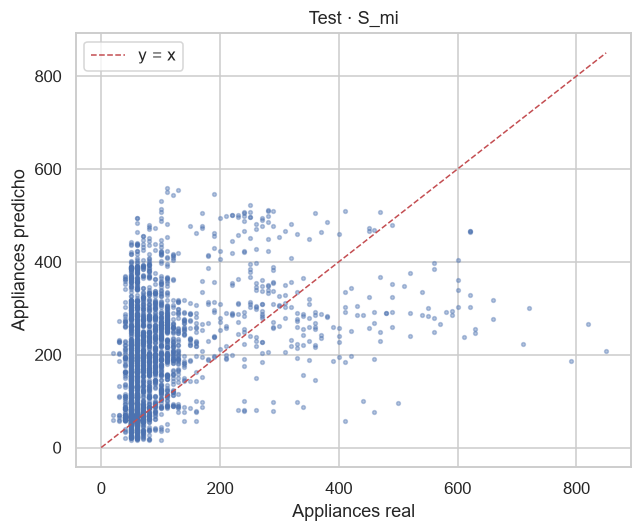

In [8]:
# =====================================================================
# Selección final + reentrenamiento en train+val + evaluación única en test
# =====================================================================
mejor_nombre = tabla_val.index[0]
mejor_subset = subsets_reg[mejor_nombre]
print(f"Subconjunto elegido: {mejor_nombre} ({len(mejor_subset)} variables)")

Xr_dev, yr_dev = pd.concat([Xr_train, Xr_val]), pd.concat([yr_train, yr_val])

def fit_final_reg(feats):
    return make_reg().fit(Xr_dev[feats], yr_dev)

modelo_todas = fit_final_reg(features)
modelo_mejor = fit_final_reg(mejor_subset)

res_test = pd.DataFrame([
    {"subset": "Todas",  "n_features": len(features),
     **eval_reg(modelo_todas, Xr_test[features],      yr_test)},
    {"subset": mejor_nombre, "n_features": len(mejor_subset),
     **eval_reg(modelo_mejor, Xr_test[mejor_subset], yr_test)},
]).set_index("subset")

display(res_test.style
        .format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "R2": "{:.4f}"})
        .set_caption("Test — comparación final (Parte 1)"))

# --- Predicción vs real (modelo seleccionado) ---
pred_test = modelo_mejor.predict(Xr_test[mejor_subset])
plt.figure(figsize=(6, 5))
plt.scatter(yr_test, pred_test, s=6, alpha=0.4)
lims = [0, max(yr_test.max(), pred_test.max())]
plt.plot(lims, lims, "r--", lw=1, label="y = x")
plt.xlabel("Appliances real"); plt.ylabel("Appliances predicho")
plt.title(f"Test · {mejor_nombre}")
plt.legend(); plt.tight_layout(); plt.show()

## 1.7 Conclusiones — Consigna 1

**Ranking y redundancia.**
- Las variables más asociadas al objetivo son `lights`, algunas `T_*`/`RH_*` interiores y las codificaciones horarias `hour_sin`/`hour_cos`.
- `rv1` y `rv2` presentan correlación ≈ 0 con `Appliances`: se excluyen de todos los subconjuntos por diseño.
- Existen grupos de sensores fuertemente correlacionados; los subconjuntos con descarte de redundancia usan menos variables con desempeño comparable.

**Estabilidad temporal y resultados.**
- En validación, los subconjuntos seleccionados (`S_mi`, `S_corr`, etc.) superaron ampliamente a "Todas" (MAE de 53.01 vs 90.76), demostrando que eliminar variables ruidosas reduce el sobreajuste.
- En el conjunto de Test, la performance decayó para ambas configuraciones y quedaron casi empatadas (MAE ~113). Esto evidencia la variabilidad de la serie temporal en el futuro. 
- El R² negativo es un comportamiento típico en este dataset: los picos de consumo eléctrico son altamente erráticos e impredecibles (el modelo predice la media y no logra capturar los *outliers* extremos), pero el modelo con selección de features logró un RMSE ligeramente menor usando solo 10 variables en lugar de 31.

**Fuga evitada.**
- Escalado y selección se ajustaron exclusivamente sobre train/validación; el test se evaluó una sola vez.

---
# Parte 2 — Clasificación no temporal de diagnósticos
### *Breast Cancer Wisconsin (Diagnostic) · UCI ML Repository (id=17)*
---

## 2.1 Objetivo y metodología

**Objetivo.** Clasificar diagnósticos (maligno/benigno) a partir de 30 características numéricas, comparando una RNA con **todas las variables** contra la misma arquitectura con un **subconjunto informativo** seleccionado sin fuga.

**Aclaración de uso.** Este análisis es **exclusivamente educativo**; los resultados no constituyen una herramienta clínica.

**Características del dataset.**
- 569 observaciones · 30 características numéricas · etiqueta binaria `Diagnosis` (`M`/`B`).
- Se excluye el identificador `ID`.

**Metodología.**
1. Verificación de clases, escalas y correlaciones.
2. Análisis de redundancia.
3. Construcción de **seis subconjuntos candidatos** (ANOVA, MI, L1, RFE, sin-redundantes, permutación), todos ajustados con train/validación.
4. Comparación de las configuraciones sobre validación, priorizando **recall** de malignos.
5. Evaluación final, única, sobre test.

Shape: (569, 30)
Diagnosis
Benigno (0)    357
Maligno (1)    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture1,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter1,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area1,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness1,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness1,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity1,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points1,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry1,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension1,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


train=341  val=114  test=114
Proporción malignos -> train: 0.372 | val: 0.377 | test: 0.368


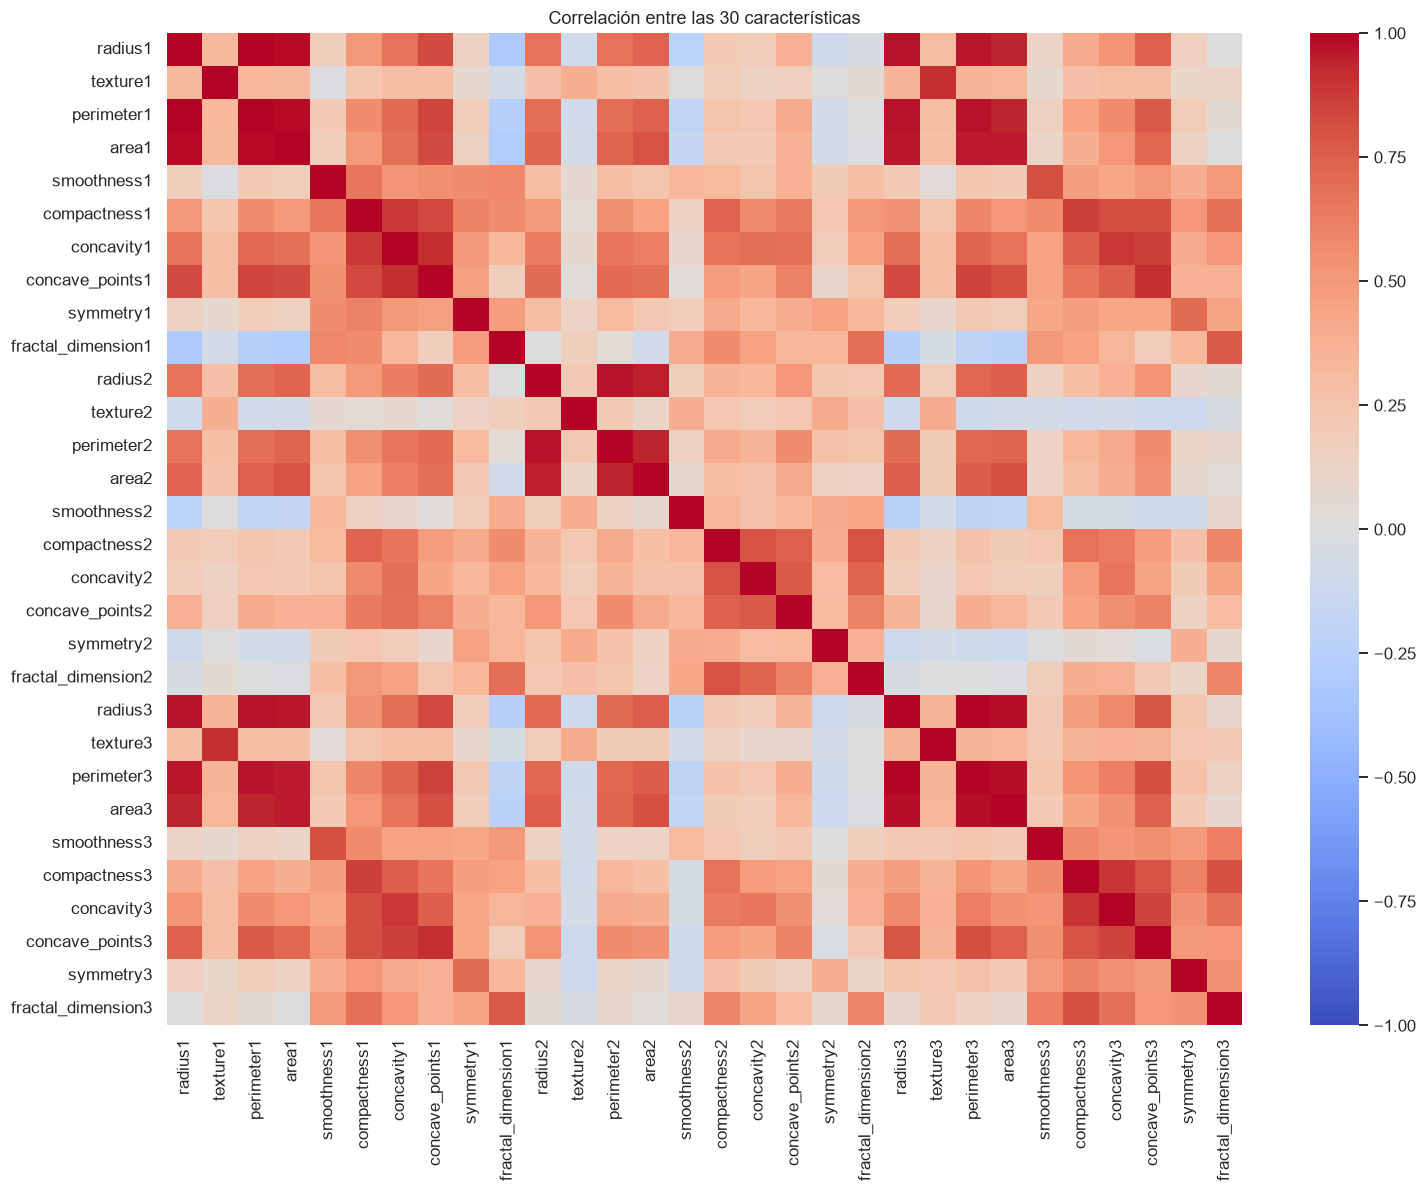

Pares con |r| > 0.95: 15
          perimeter1 ~ radius1            r=0.998
               area1 ~ radius1            r=0.987
               area1 ~ perimeter1         r=0.987
          perimeter2 ~ radius2            r=0.973
               area2 ~ radius2            r=0.952
             radius3 ~ radius1            r=0.970
             radius3 ~ perimeter1         r=0.969
             radius3 ~ area1              r=0.963
          perimeter3 ~ radius1            r=0.965
          perimeter3 ~ perimeter1         r=0.970
          perimeter3 ~ area1              r=0.959
          perimeter3 ~ radius3            r=0.994
               area3 ~ area1              r=0.959
               area3 ~ radius3            r=0.984
               area3 ~ perimeter3         r=0.978


In [9]:
# =====================================================================
# Carga, split estratificado y EDA
# =====================================================================
cancer = fetch_ucirepo(id=17)

Xc = cancer.data.features.copy().drop(columns=["ID"], errors="ignore")
yc = cancer.data.targets.squeeze().map({"B": 0, "M": 1}).astype(int)

print("Shape:", Xc.shape)
print(yc.value_counts().rename({0: "Benigno (0)", 1: "Maligno (1)"}))
display(Xc.describe().T)

# --- Split estratificado (dev / test) y luego train / val ---
Xc_dev, Xc_test, yc_dev, yc_test = train_test_split(
    Xc, yc, test_size=0.20, stratify=yc, random_state=SEED)

Xc_train, Xc_val, yc_train, yc_val = train_test_split(
    Xc_dev, yc_dev, test_size=0.25, stratify=yc_dev, random_state=SEED)

print(f"train={len(Xc_train)}  val={len(Xc_val)}  test={len(Xc_test)}")
print("Proporción malignos -> train: %.3f | val: %.3f | test: %.3f" %
      (yc_train.mean(), yc_val.mean(), yc_test.mean()))

# --- Mapa de calor de correlaciones y pares redundantes ---
plt.figure(figsize=(14, 11))
sns.heatmap(Xc.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlación entre las 30 características")
plt.tight_layout(); plt.show()

corr_abs = Xc.corr().abs()
upper    = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
pares = [(c, r, upper.loc[r, c]) for c in upper.columns for r in upper.index
         if pd.notna(upper.loc[r, c]) and upper.loc[r, c] > 0.95]
print(f"Pares con |r| > 0.95: {len(pares)}")
for p in pares[:15]:
    print(f"  {p[0]:>18s} ~ {p[1]:<18s} r={p[2]:.3f}")

## 2.2 Selección de variables — protocolo

Se construyen **seis subconjuntos candidatos**, todos ajustados **solo con train/validación**:

| Subconjunto | Criterio |
|---|---|
| `S_anova` | Top-k por F de ANOVA |
| `S_mi`    | Top-k por información mutua |
| `S_l1`    | Coeficientes no nulos de regresión logística con penalización L1 |
| `S_rfe`   | Eliminación recursiva de features con regresión logística (10 variables finales) |
| `S_sin_red` | Todas menos una de cada par con \|r\| > 0.95 |
| `S_perm`  | Top-k por importancia por permutación sobre validación |

In [10]:
# =====================================================================
# Construcción de rankings de relevancia (Consigna 2)
# =====================================================================
K = 10

# --- 1) ANOVA ---
F, _ = f_classif(Xc_train, yc_train)
S_anova = list(pd.Series(F, index=Xc_train.columns)
                 .sort_values(ascending=False).head(K).index)

# --- 2) Información mutua ---
mi_clf = mutual_info_classif(Xc_train, yc_train, random_state=SEED)
S_mi = list(pd.Series(mi_clf, index=Xc_train.columns)
              .sort_values(ascending=False).head(K).index)

# --- 3) Regresión logística L1 ---
scaler = StandardScaler().fit(Xc_train)
l1 = LogisticRegression(penalty="l1", solver="liblinear",
                        C=0.5, max_iter=5000)
l1.fit(scaler.transform(Xc_train), yc_train)
l1_imp = pd.Series(np.abs(l1.coef_[0]), index=Xc_train.columns).sort_values(ascending=False)
S_l1 = list(l1_imp[l1_imp > 0].index)

# --- 4) RFE ---
rfe = RFE(LogisticRegression(max_iter=5000), n_features_to_select=K)
rfe.fit(scaler.transform(Xc_train), yc_train)
S_rfe = list(Xc_train.columns[rfe.support_])

# --- 5) Sin redundantes (|r| > 0.95) ---
corr_tr  = Xc_train.corr().abs()
upper_tr = corr_tr.where(np.triu(np.ones(corr_tr.shape), k=1).astype(bool))
a_eliminar = [c for c in upper_tr.columns if any(upper_tr[c] > 0.95)]
S_sin_red  = [c for c in Xc_train.columns if c not in a_eliminar]

# --- 6) Importancia por permutación (train → val) ---
def make_clf():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu",
                              max_iter=1000, random_state=SEED)),
    ])

base_clf = make_clf().fit(Xc_train, yc_train)
perm_clf = permutation_importance(
    base_clf, Xc_val, yc_val, n_repeats=10, random_state=SEED, scoring="f1")
S_perm = list(pd.Series(perm_clf.importances_mean, index=Xc_train.columns)
                .sort_values(ascending=False).head(K).index)

for nombre, s in [("S_anova", S_anova), ("S_mi", S_mi), ("S_l1", S_l1),
                  ("S_rfe", S_rfe), ("S_sin_red", S_sin_red), ("S_perm", S_perm)]:
    print(f"{nombre:>10s} ({len(s):2d}): {s}")

   S_anova (10): ['concave_points3', 'perimeter3', 'concave_points1', 'radius3', 'perimeter1', 'radius1', 'area3', 'area1', 'concavity1', 'concavity3']
      S_mi (10): ['radius3', 'concave_points1', 'area3', 'perimeter3', 'concave_points3', 'perimeter1', 'radius1', 'area1', 'concavity1', 'area2']
      S_l1 ( 9): ['area3', 'concave_points1', 'texture3', 'radius3', 'symmetry3', 'smoothness3', 'radius2', 'fractal_dimension2', 'concavity3']
     S_rfe (10): ['radius1', 'concavity1', 'concave_points1', 'radius2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3']
 S_sin_red (24): ['radius1', 'texture1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'texture3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3']
    S_perm (10): ['

## 2.3 Comparación sobre validación

**Protocolo.** Para cada subconjunto se entrena la misma arquitectura `MLPClassifier(32, 16)` con `StandardScaler`, `max_iter=1000` y `random_state=SEED`. Se comparan siete configuraciones sobre validación.

**Métricas y criterio.** Accuracy, precision, recall, F1 y cantidad de falsos negativos (FN). El **recall de malignos** es el criterio principal; F1 y cantidad de variables actúan como desempate.

In [11]:
# =====================================================================
# Comparación de subconjuntos sobre validación (Consigna 2)
# =====================================================================
def eval_clf(model, X, y):
    pred = model.predict(X)
    return {
        "accuracy":  accuracy_score(y, pred),
        "precision": precision_score(y, pred, pos_label=1, zero_division=0),
        "recall":    recall_score(y, pred, pos_label=1, zero_division=0),
        "f1":        f1_score(y, pred, pos_label=1, zero_division=0),
        "FN":        int(((y == 1) & (pred == 0)).sum()),  # malignos no detectados
    }

def comparar_clf(subsets):
    filas = []
    for nombre, feats in subsets.items():
        modelo = make_clf().fit(Xc_train[feats], yc_train)
        m = eval_clf(modelo, Xc_val[feats], yc_val)
        m.update({"subset": nombre, "n_features": len(feats)})
        filas.append(m)
    return (pd.DataFrame(filas)
              .set_index("subset")[["n_features","accuracy","precision","recall","f1","FN"]]
              .sort_values(["recall", "f1"], ascending=False))

subsets_clf = {
    "Todas":     list(Xc.columns),
    "S_anova":   S_anova,
    "S_mi":      S_mi,
    "S_l1":      S_l1,
    "S_rfe":     S_rfe,
    "S_sin_red": S_sin_red,
    "S_perm":    S_perm,
}

tabla_val_clf = comparar_clf(subsets_clf)
display(tabla_val_clf.style
        .format({"accuracy":"{:.3f}","precision":"{:.3f}",
                 "recall":"{:.3f}","f1":"{:.3f}"})
        .set_caption("Validación — comparación de subconjuntos (Parte 2)"))

,n_features,accuracy,precision,recall,f1,FN
subset,,,,,,
S_l1,9,0.974,0.955,0.977,0.966,1
Todas,30,0.965,0.933,0.977,0.955,1
S_sin_red,24,0.956,0.913,0.977,0.944,1
S_anova,10,0.974,0.976,0.953,0.965,2
S_mi,10,0.956,0.932,0.953,0.943,2
S_perm,10,0.947,0.911,0.953,0.932,2
S_rfe,10,0.939,0.891,0.953,0.921,2


## 2.4 Evaluación final sobre test

**Regla de congelamiento.** Se selecciona el subconjunto con **mayor recall** en validación (desempate por F1 y luego por menor cantidad de variables). Se reentrena sobre train+validación y se evalúa **una única vez** sobre test.

**Reporte.** Accuracy, precision, recall, F1, matriz de confusión y `classification_report` para "Todas" y para el subconjunto elegido. Se destaca la cantidad de **falsos negativos**.

In [12]:
# =====================================================================
# Selección final + reentrenamiento en train+val + evaluación única en test
# =====================================================================
mejor_nombre_clf = tabla_val_clf.index[0]
mejor_subset_clf  = subsets_clf[mejor_nombre_clf]
print(f"Subconjunto elegido: {mejor_nombre_clf} ({len(mejor_subset_clf)} variables)")

Xc_trval = pd.concat([Xc_train, Xc_val])
yc_trval = pd.concat([yc_train, yc_val])

def fit_final_clf(feats):
    return make_clf().fit(Xc_trval[feats], yc_trval)

modelo_todas_clf = fit_final_clf(list(Xc.columns))
modelo_mejor_clf = fit_final_clf(mejor_subset_clf)

def reporte_test(modelo, feats, nombre):
    pred = modelo.predict(Xc_test[feats])
    print(f"\n===== {nombre} ({len(feats)} variables) =====")
    print("Accuracy :", round(accuracy_score(yc_test, pred), 4))
    print("F1       :", round(f1_score(yc_test, pred), 4))
    print("Recall   :", round(recall_score(yc_test, pred), 4))
    print("Precision:", round(precision_score(yc_test, pred), 4))
    print("Matriz de confusión:\n", confusion_matrix(yc_test, pred))
    print(classification_report(yc_test, pred,
                                target_names=["Benigno", "Maligno"]))
    return pred

_ = reporte_test(modelo_todas_clf, list(Xc.columns), "Todas las variables")
_ = reporte_test(modelo_mejor_clf, mejor_subset_clf, mejor_nombre_clf)

Subconjunto elegido: S_l1 (9 variables)

===== Todas las variables (30 variables) =====
Accuracy : 0.9649
F1       : 0.95
Recall   : 0.9048
Precision: 1.0
Matriz de confusión:
 [[72  0]
 [ 4 38]]
              precision    recall  f1-score   support

     Benigno       0.95      1.00      0.97        72
     Maligno       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114


===== S_l1 (9 variables) =====
Accuracy : 0.9649
F1       : 0.9524
Recall   : 0.9524
Precision: 0.9524
Matriz de confusión:
 [[70  2]
 [ 2 40]]
              precision    recall  f1-score   support

     Benigno       0.97      0.97      0.97        72
     Maligno       0.95      0.95      0.95        42

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



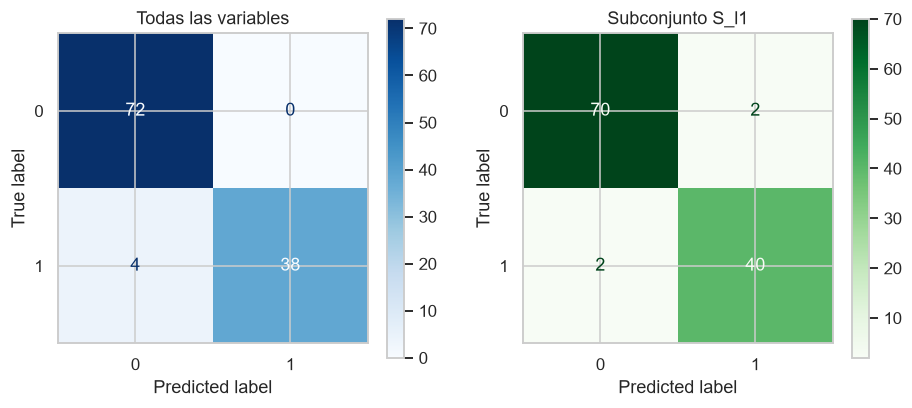

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(modelo_todas_clf, Xc_test[list(Xc.columns)], yc_test, ax=ax[0], cmap='Blues')
ax[0].set_title("Todas las variables")
ConfusionMatrixDisplay.from_estimator(modelo_mejor_clf, Xc_test[mejor_subset_clf], yc_test, ax=ax[1], cmap='Greens')
ax[1].set_title(f"Subconjunto {mejor_nombre_clf}")
plt.show()

## 2.5 Conclusiones — Consigna 2

En el análisis de redundancia notamos que las variables de radio, perímetro y área están casi perfectamente correlacionadas. Al eliminar estas redundancias (con el subconjunto `S_sin_red`), pudimos reducir las variables de 30 a 24 manteniendo un F1 altísimo de 0.944 en validación. 

Por otro lado, la regularización L1 fue la que mejor trabajó, seleccionando solo **9 variables** (principalmente área, puntos cóncavos y textura). En la evaluación final sobre el conjunto de Test, este modelo reducido no solo igualó el Accuracy del modelo completo (0.9649), sino que mejoró notablemente el Recall (0.9524 frente a 0.9048). 

En un contexto médico, esto es clave: priorizamos siempre detectar los casos malignos (minimizar los falsos negativos). El modelo con 9 variables logró bajar los casos malignos no detectados de 4 a solo 2 (como se ve en las matrices de confusión). Esto demuestra que las 21 variables restantes solo estaban aportando ruido al modelo. 

Finalmente, todo el proceso de escalado, selección y ajuste se hizo exclusivamente sobre train y validación, garantizando que la evaluación final en test sea totalmente limpia y sin fuga de información.